In [1]:
import polars as pl
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent          # the notebook lives in notebooks/
book = pl.read_parquet(ROOT / "data" / "processed" / "book_states.parquet")
trades = pl.read_parquet(ROOT / "data" / "processed" / "trades.parquet")
print(book.shape, trades.shape)
book.head()

(7451501, 11) (39096, 10)


timestamp,bid_prices,bid_sizes,ask_prices,ask_sizes,ofi,symbol,session,mid,spread,dmid
"datetime[μs, UTC]",f64,i64,f64,i64,i64,str,str,f64,f64,f64
2026-09-11 12:00:01.118533 UTC,762.28,100,null,null,null,"""SPY""","""pre""",null,null,null
2026-09-11 12:00:01.118620 UTC,762.28,100,762.41,100,null,"""SPY""","""pre""",762.345,0.13,null
2026-09-11 12:00:01.369084 UTC,762.31,100,762.41,100,100,"""SPY""","""pre""",762.36,0.1,0.015
2026-09-11 12:00:01.517991 UTC,762.28,100,762.41,100,-100,"""SPY""","""pre""",762.345,0.13,-0.015
2026-09-11 12:00:01.628174 UTC,762.31,100,762.41,100,100,"""SPY""","""pre""",762.36,0.1,0.015


share of exactly zero: 0.21756358967113817
1%, 50%, 99%, 99.9% percentiles: [-200.0, 0.0, 200.0, 1500.0]


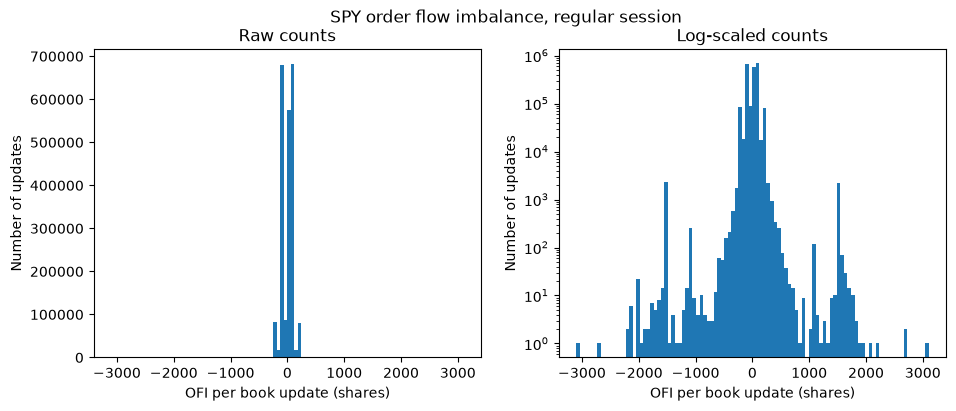

In [2]:
(ROOT / "figures").mkdir(exist_ok=True)

spy = (book.filter((pl.col("symbol") == "SPY") & (pl.col("session") == "regular"))
           .drop_nulls("ofi"))
ofi = spy["ofi"].to_numpy()
print("share of exactly zero:", (ofi == 0).mean())
print("1%, 50%, 99%, 99.9% percentiles:", [float(x) for x in
      __import__("numpy").percentile(ofi, [1, 50, 99, 99.9])])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(ofi, bins=100)
ax[0].set_title("Raw counts")
ax[1].hist(ofi, bins=100)
ax[1].set_yscale("log")
ax[1].set_title("Log-scaled counts")
for a in ax:
    a.set_xlabel("OFI per book update (shares)")
    a.set_ylabel("Number of updates")
fig.suptitle("SPY order flow imbalance, regular session")
fig.savefig(ROOT / "figures" / "01_spy_ofi_distribution.png", dpi=150, bbox_inches="tight")
plt.show()